# Módulo 2 — Tendência e sazonalidade
## Seção 1 — Tendências determinísticas e estocásticas: teoria, estimação e Python

**Estado editorial:** primeira seção desenvolvida; sazonalidade, indicadores e componentes harmônicas ficarão nas seções seguintes do **mesmo módulo**. A programação é parte integrante da explicação matemática, não um módulo independente.

**Fundamentação verificada:** Morettin e Toloi, *Análise de séries temporais: modelos lineares univariados*, vol. 1, 3ª ed., cap. 3, § 3.2, pp. impressas 52–53 (páginas 71–72 deste PDF). Nesses trechos, os autores introduzem o modelo $Z_t=T_t+a_t$, o ajuste de tendências polinomiais e o critério de mínimos quadrados. **Complementação didática original:** comparação formal com passeio aleatório com deriva, exemplos numéricos específicos, códigos e gráficos sintéticos deste texto. O desenvolvimento integral do passeio aleatório e dos testes de raiz unitária está reservado ao Módulo 3.

**Pré-requisitos:** função média, variância e ruído branco; somatórios, derivadas de polinômios, vetores e noções básicas de Python.

### 1. Pergunta norteadora

Uma série de temperaturas, consumo ou produção pode crescer ao longo do tempo. A linha ascendente é uma propriedade determinística da função média, ou decorre da acumulação de choques aleatórios? Mesmo quando duas séries têm valores médios idênticos, esses mecanismos conduzem a estruturas de incerteza diferentes.

**Objetivos:** (i) diferenciar tendência determinística e estocástica; (ii) explicar a função média e a variância em cada modelo; (iii) deduzir mínimos quadrados em uma reta; (iv) implementar o cálculo manualmente e por álgebra linear; (v) interpretar gráficos de muitas trajetórias; (vi) reconhecer limitações dos métodos.

### 2. Um modelo inicial para tendência

Em Morettin e Toloi, § 3.2, p. 52, um ponto de partida sem componente sazonal explícita é

$$Z_t=T_t+a_t,$$

em que $Z_t$ é a variável observada no instante $t$, $T_t$ representa a tendência e $a_t$ é o componente aleatório, inicialmente tratado como ruído branco de variância $\sigma_a^2$. O modelo é **aditivo**: a escala do erro não é multiplicada pelo nível da tendência. A restrição de ausência de sazonalidade é provisória e será retirada adiante neste módulo.

Tendência não é sinônimo de previsão: trata-se de uma estrutura que queremos entender e, quando apropriado, estimar. Tampouco um gráfico crescente, isoladamente, demonstra uma tendência estatística.

### 3. Tendência determinística

Considere $Z_t=\alpha+\beta t+\varepsilon_t$, com $E[\varepsilon_t]=0$ e $\operatorname{Var}(\varepsilon_t)=\sigma^2<\infty$ para todo $t$. Aqui $\alpha$ é o nível da função de tendência no instante zero e $\beta$ é sua variação por unidade de tempo; as unidades de $\beta$ são unidades da variável por unidade temporal.

A função média é

$$E[Z_t]=\alpha+\beta t+E[\varepsilon_t]=\alpha+\beta t.$$

A parte determinística não contribui para a variância:

$$\operatorname{Var}(Z_t)=\operatorname{Var}(\varepsilon_t)=\sigma^2.$$

Para instantes $s,t$,

$$\operatorname{Cov}(Z_s,Z_t)=\operatorname{Cov}(\varepsilon_s,\varepsilon_t).$$

Se as perturbações forem ruído branco, essa covariância é zero para $s\neq t$. **Isso não garante independência**, salvo hipóteses adicionais. Se $\beta\ne0$, $Z_t$ não é fracamente estacionário por ter média variável. Contudo, retirar a tendência verdadeira produz $Z_t-(\alpha+\beta t)=\varepsilon_t$, que é fracamente estacionário sob as hipóteses descritas.

**Generalização:** Morettin e Toloi, § 3.2.1, pp. 52–53, consideram $T_t=\beta_0+\beta_1t+\cdots+\beta_m t^m$. Polinômios são úteis para descrever um trecho da série, mas podem extrapolar mal fora da região observada.

### 4. Tendência estocástica: primeira comparação

Considere o processo definido, para inteiros $t\geq1$, por

$$W_0=\alpha,\qquad W_t=W_{t-1}+\beta+\varepsilon_t,$$

em que as inovações $\varepsilon_t$ são independentes, com média zero e variância comum $\sigma^2$. Trata-se de um **passeio aleatório com deriva** $\beta$. Por substituições repetidas:

$$W_1=\alpha+\beta+\varepsilon_1,$$

$$W_2=\alpha+2\beta+\varepsilon_1+\varepsilon_2,$$

$$\boxed{W_t=\alpha+\beta t+\sum_{k=1}^{t}\varepsilon_k.}$$

Logo,

$$E[W_t]=\alpha+\beta t,$$

$$\begin{aligned}\operatorname{Var}(W_t)&=\operatorname{Var}\left(\sum_{k=1}^t\varepsilon_k\right)\\&=\sum_{k=1}^t\operatorname{Var}(\varepsilon_k)\\&=t\sigma^2.\end{aligned}$$

No passo intermediário, a independência permite anular as covariâncias cruzadas. Para $s,t\geq0$,

$$\operatorname{Cov}(W_s,W_t)=\sigma^2\min(s,t).$$

**Demonstração:** se $s\le t$, os primeiros $s$ choques estão presentes nas duas somas. Os choques posteriores são independentes daqueles da primeira soma; portanto, restam $s$ termos de variância $\sigma^2$. Pela simetria, vale a fórmula para qualquer par.

**Consequência:** apesar de $E[W_t]=E[Z_t]$, temos $\operatorname{Var}(Z_t)=\sigma^2$ e $\operatorname{Var}(W_t)=t\sigma^2$. No segundo caso, o efeito de um choque fica incorporado ao nível futuro da série. Chamaremos esse comportamento de *tendência estocástica*, motivando o estudo formal de raízes unitárias no Módulo 3.

| Propriedade | $Z_t=\alpha+\beta t+\varepsilon_t$ | $W_t=W_{t-1}+\beta+\varepsilon_t$ |
|---|---|---|
| Média | $\alpha+\beta t$ | $\alpha+\beta t$ |
| Variância | $\sigma^2$ | $t\sigma^2$ |
| Efeito de um choque | Aparece diretamente no instante do choque | Persiste no nível dos instantes seguintes |
| Sem estacionariedade fraca da série original | Se $\beta\ne0$ | Em geral, sim, pela variância crescente |
| Transformação natural a investigar | Retirar tendência determinística estimada | Diferenças sucessivas, no Módulo 3 |

**Atenção:** a comparação usa um nível inicial fixo $W_0=\alpha$. Com nível inicial aleatório, a variância e as covariâncias devem incluir os termos correspondentes. Tampouco a estimação de $\alpha,\beta$ garante que o resíduo ajustado seja ruído branco.

### 5. Ajuste de uma tendência linear por mínimos quadrados

Suponha que observamos $(t_i,y_i)$, $i=1,\ldots,n$. Escolhemos uma reta $\widehat T(t)=b_0+b_1t$ minimizando

$$S(b_0,b_1)=\sum_{i=1}^n(y_i-b_0-b_1t_i)^2.$$

Essa expressão é a versão linear do critério polinomial apresentado em Morettin e Toloi, § 3.2.1, p. 53. Para encontrar o mínimo, derivamos em relação a cada coeficiente:

$$\frac{\partial S}{\partial b_0}=-2\sum_{i=1}^n(y_i-b_0-b_1t_i)=0,$$

$$\frac{\partial S}{\partial b_1}=-2\sum_{i=1}^nt_i(y_i-b_0-b_1t_i)=0.$$

A primeira equação fornece $\overline y=b_0+b_1\overline t$, portanto $b_0=\overline y-b_1\overline t$. Substituindo na segunda e reorganizando,

$$\boxed{\widehat\beta_1=\frac{\sum_{i=1}^n(t_i-\overline t)(y_i-\overline y)}{\sum_{i=1}^n(t_i-\overline t)^2}},\qquad \boxed{\widehat\beta_0=\overline y-\widehat\beta_1\overline t}. $$

O denominador deve ser positivo: precisamos observar ao menos dois valores distintos de tempo. O critério é uma função quadrática convexa; quando a matriz de regressão tem posto completo, sua solução é única.

#### Exemplo numérico resolvido

Tomemos cinco observações **fictícias**, com $t=(0,1,2,3,4)$ e $y=(2,3,5,4,6)$.

$$\overline t=2,\qquad\overline y=4.$$

A soma dos produtos centrados é

$$\sum(t_i-2)(y_i-4)=4+1+0+0+4=9,$$

e a soma dos quadrados do tempo centrado vale

$$\sum(t_i-2)^2=4+1+0+1+4=10.$$

Assim,

$$\widehat\beta_1=\frac9{10}=0{,}9,\qquad \widehat\beta_0=4-0{,}9(2)=2{,}2.$$

A reta ajustada é

$$\boxed{\widehat T(t)=2{,}2+0{,}9t}.$$

Os valores previstos nos tempos observados são $(2{,}2;3{,}1;4{,}0;4{,}9;5{,}8)$, e os resíduos $y_i-\widehat T(t_i)$ são $(-0{,}2;-0{,}1;1{,}0;-0{,}9;0{,}2)$. A soma dos resíduos é zero, propriedade algébrica do ajuste com intercepto, **não uma demonstração de ausência de autocorrelação**.

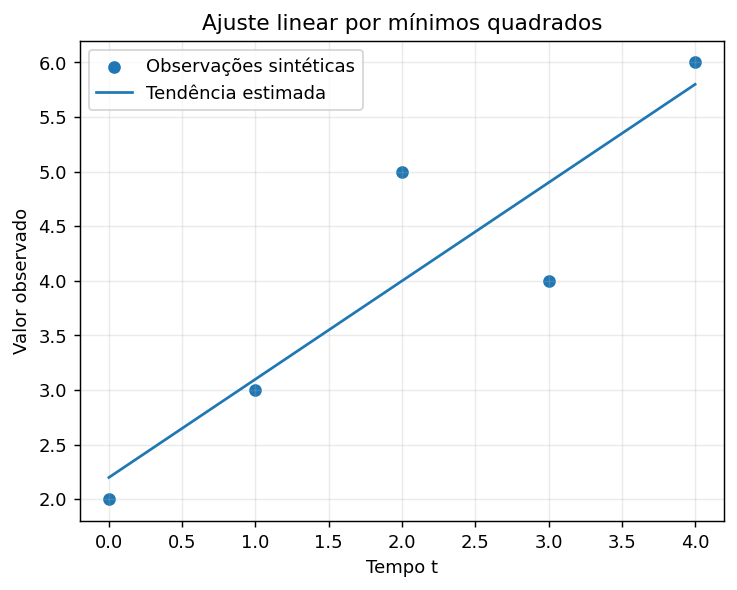

*Figura 2.1 — Dados sintéticos e reta estimada por mínimos quadrados. A inclinação de $0{,}9$ representa aumento médio ajustado por unidade de tempo; o gráfico não permite, por si só, concluir que a relação continuará indefinidamente.*

### 6. Python integrado: implementar as equações sem esconder o algoritmo

**Dependências:** Python 3, NumPy e Matplotlib. No terminal, caso necessário: `python -m pip install numpy matplotlib`. NumPy manipula vetores e matrizes; Matplotlib cria as figuras. O código integral desta seção também está no arquivo complementar `modulo_02_exemplo.py`, para execução independente.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Dados sintéticos, não uma série meteorológica real
x = np.arange(5, dtype=float)             # vetor [0., 1., 2., 3., 4.]
y = np.array([2, 3, 5, 4, 6], dtype=float)

# Médias e somas da fórmula deduzida
x_bar = x.mean()
y_bar = y.mean()
numerador = np.sum((x - x_bar) * (y - y_bar))
denominador = np.sum((x - x_bar) ** 2)
beta_1 = numerador / denominador
beta_0 = y_bar - beta_1 * x_bar

y_hat = beta_0 + beta_1 * x
residuos = y - y_hat
print(beta_0, beta_1)        # 2.2 0.9
print(residuos)             # [-0.2, -0.1, 1., -0.9, 0.2]

fig, ax = plt.subplots()
ax.scatter(x, y, label='Observações sintéticas')
ax.plot(x, y_hat, label='Tendência estimada')
ax.set(xlabel='Tempo t', ylabel='Valor observado', title='Ajuste linear por mínimos quadrados')
ax.legend()
ax.grid(alpha=0.25)
plt.show()


**Como ler as operações:** `np.arange(5)` constrói os cinco instantes (o limite superior 5 não é incluído); `np.array` converte os valores em vetor numérico; `mean` calcula uma média aritmética; `np.sum` implementa a soma $\sum$; `**2` eleva cada elemento ao quadrado; `x - x_bar` subtrai a mesma média de cada elemento. `plt.subplots()` cria uma figura e seus eixos; `scatter` representa pontos e `plot` desenha a reta.

O cálculo acima é **manual no sentido algorítmico**: usa diretamente a fórmula, sem uma função de regressão pronta. Mais adiante, ao introduzir matrizes, podemos conferir o resultado por `np.linalg.lstsq(X, y, rcond=None)`, em que $X$ contém uma coluna de 1 e outra de tempos. Essa função utiliza métodos de álgebra linear mais adequados numericamente do que calcular explicitamente $(X^TX)^{-1}$.

### 7. Python integrado: simular dois mecanismos diferentes

A seguir, consideramos $M=600$ trajetórias com $N=80$ instantes, $\alpha=2$, $\beta=0{,}15$ e $\sigma=1$. `default_rng` cria um gerador pseudoaleatório reproduzível, enquanto `normal` fornece uma matriz de sorteios independentes normais. A **normalidade é uma escolha para a simulação**; os resultados de média e variância apresentados nas Seções 3 e 4 não dependem dela.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261109)
M, N = 600, 80
alpha, beta, sigma = 2.0, 0.15, 1.0
t = np.arange(N)

# Cada linha é uma trajetória; cada coluna, um instante
ruidos = rng.normal(0, sigma, size=(M, N))
Z = alpha + beta * t + ruidos

# A primeira coluna de W é W_0=alpha, sem inovação inicial
inovacoes = rng.normal(0, sigma, size=(M, N))
termos = np.column_stack([np.zeros(M), inovacoes[:, 1:]])
W = alpha + beta * t + np.cumsum(termos, axis=1)

media_teorica = alpha + beta * t
var_teorica_Z = np.full(N, sigma**2)
var_teorica_W = sigma**2 * t

# axis=0: calcular entre trajetórias, para cada instante
var_estimada_Z = Z.var(axis=0, ddof=0)
var_estimada_W = W.var(axis=0, ddof=0)

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex='col')
for j in range(8):
    axs[0, 0].plot(t, Z[j], alpha=0.7)
    axs[0, 1].plot(t, W[j], alpha=0.7)
for k, dados, var_teorica, titulo in [
    (0, Z, var_teorica_Z, 'Determinística'),
    (1, W, var_teorica_W, 'Estocástica')]:
    axs[0, k].plot(t, media_teorica, 'k--', label='Média teórica')
    axs[0, k].set_title(titulo)
    axs[0, k].legend()
    axs[1, k].plot(t, dados.var(axis=0), label='Estimativa')
    axs[1, k].plot(t, var_teorica, 'k--', label='Valor teórico')
    axs[1, k].set_xlabel('Tempo t')
    axs[1, k].set_ylabel('Variância')
    axs[1, k].legend()
plt.tight_layout()
plt.show()


**Por que `axis=1` em `cumsum`?** `termos` tem formato `(M,N)`: cada linha contém a sequência de choques de uma trajetória. A soma acumulada precisa avançar ao longo das colunas do tempo, isto é, ao longo do eixo 1. Já `var(axis=0)` calcula, para cada coluna de tempo, a variabilidade entre as $M$ realizações.

`ddof=0` usa denominador $M$ para a dispersão empírica dos sorteios; `ddof=1` usa $M-1$, convenção que oferece um estimador não viesado da variância populacional sob observações i.i.d. em cada instante. A escolha deve ser declarada ao confrontar a estimativa com a variância teórica.

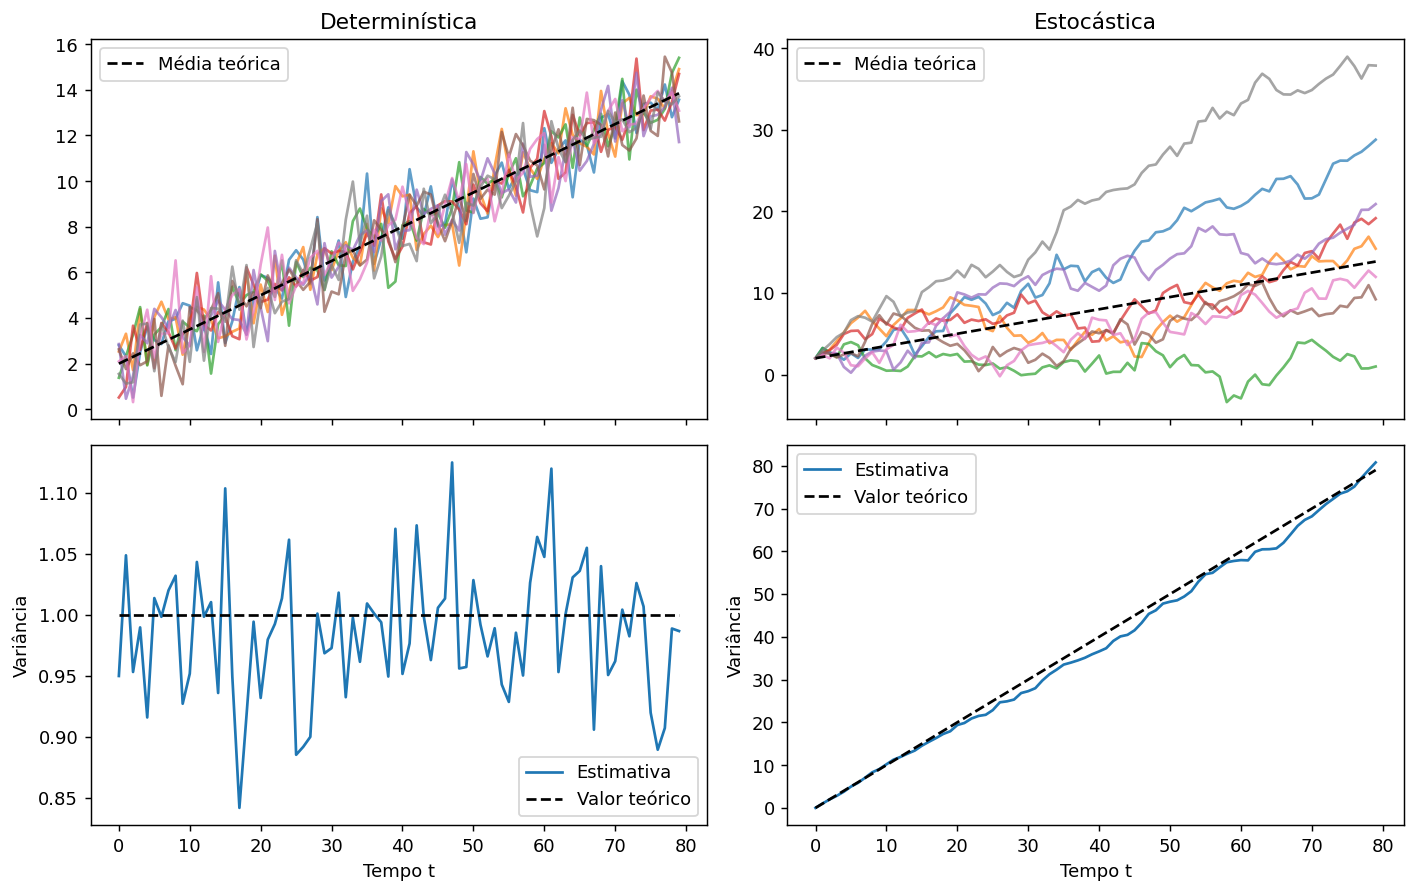

*Figura 2.2 — Oito realizações de cada processo (painéis superiores) e variâncias calculadas a partir das 600 trajetórias (painéis inferiores). As linhas tracejadas indicam as grandezas teóricas. Pequenas diferenças resultam da amostra finita, não de falhas nas identidades matemáticas.*

**Resultados de conferência, com a semente indicada:** no instante $t=40$, a variância teórica do processo determinístico é $1$, enquanto a do passeio aleatório é $40$. Na execução utilizada para gerar as figuras, as variâncias empíricas com denominador $M$ foram aproximadamente $0{,}95$ e $36{,}59$. Como cada execução usa a mesma semente e o mesmo algoritmo, os resultados são reproduzíveis sob as dependências utilizadas; mudanças de implementações podem alterar detalhes das sequências pseudoaleatórias.

### 8. Limitações e interpretação

1. **Ajuste não é mecanismo gerador comprovado.** Uma reta obtida por mínimos quadrados pode descrever bem um trecho, mesmo quando o processo gerador tem tendência estocástica.
2. **Dependência serial importa.** As fórmulas algébricas dos coeficientes de mínimos quadrados continuam definidas, mas sua interpretação inferencial, erros-padrão e propriedades de consistência exigem hipóteses adicionais.
3. **Uma trajetória não revela a variância entre trajetórias.** Os gráficos de variâncias foram construídos com um ensemble simulado; em dados reais, normalmente dispomos de uma série observada.
4. **Extrapolação é arriscada.** Mesmo uma reta aparentemente adequada no período observado pode falhar em períodos posteriores.
5. **Comparações de treino/teste precisam ser cronológicas.** Em problemas preditivos, ajuste a tendência apenas com observações do treino, não com informações futuras.
6. **A simulação não demonstra uma hipótese probabilística.** A prova de $\operatorname{Var}(W_t)=t\sigma^2$ depende das suposições sobre as inovações, não da aparência do gráfico.

### 9. Exercícios

**Conceitual.** Dois processos possuem a mesma função média $E[X_t]=3+0{,}1t$. Isso significa que apresentam a mesma estrutura de dependência temporal? Justifique por meio de variâncias e covariâncias.

**Cálculo.** Deduzir $\operatorname{Cov}(W_s,W_t)=\sigma^2\min(s,t)$ para o passeio aleatório com deriva e nível inicial fixo. Explicitar a utilização da independência.

**Matemática de estimação.** Para os pontos da Seção 5, calcular a soma dos resíduos e a soma dos quadrados dos resíduos. Conferir manualmente que as derivadas parciais da função objetivo são nulas em $(2{,}2,0{,}9)$.

**Python, nível 1.** Sem usar `np.mean`, implementar um laço que calcule a média de cada coluna de uma matriz `Z` e comparar com `Z.mean(axis=0)`.

**Python, nível 2.** Repetir a Figura 2.2 para $M=20$, $M=200$ e $M=2000$. Descrever como muda a estabilidade das curvas estimadas em relação às curvas teóricas. Evitar concluir que haverá melhora monotônica em todo instante de uma única repetição.

**Discussão.** Investigar por que retirar uma reta estimada de uma série não é equivalente, em geral, à primeira diferença. O aprofundamento formal ficará no Módulo 3.

**Conferência selecionada:** os resíduos do exemplo são $(-0{,}2,-0{,}1,1,-0{,}9,0{,}2)$; sua soma é $0$ e a soma dos quadrados é $1{,}90$. Os demais exercícios foram deixados para resolução ativa.

### 10. Síntese e próximo tópico

A principal distinção desta seção é que **a média de uma série não determina a natureza de sua tendência**. Uma componente determinística pode deslocar o centro do processo sem aumentar sua variância, ao passo que a acumulação de inovações altera a dispersão e as covariâncias com o passar do tempo. Mínimos quadrados fornece uma ferramenta de descrição da tendência média, mas não resolve automaticamente a questão do mecanismo probabilístico.

A próxima seção do **mesmo Módulo 2** introduzirá a sazonalidade, os períodos sazonais e a diferença entre comportamento sazonal determinístico e estocástico. Depois, a estimação por variáveis indicadoras e componentes harmônicas será desenvolvida matematicamente e implementada em Python dentro das respectivas seções.

### Referências e rastreabilidade

- MORETTIN, Pedro A.; TOLOI, Clélia M. C. *Análise de séries temporais: modelos lineares univariados*. Vol. 1, 3ª ed. Blucher, 2018. Cap. 3, § 3.2, pp. 52–53, consultadas visualmente no PDF disponibilizado. O livro apresenta o modelo aditivo inicial e a formulação polinomial pelo critério de mínimos quadrados; não se atribuem a essas páginas os experimentos sintéticos criados aqui.
- `PLANO_MODULOS_PRIORITARIOS.md`, item Módulo 2: objetivos e limites editoriais adotados.
- `mapeamento-conteudos-series-temporais.md`, Blocos A e C: orientação pedagógica para tendência e sazonalidade; não constitui prova matemática independente.
- A dedução comparativa com passeio aleatório, os dados fictícios, as figuras e os códigos são complementações didáticas originais deste material.